# Causal FIR Backpropagation for One Tracked Example

This notebook tests a zero-future-sample causal FIR approximation to the inverse backpropagation operator. It loads one lock-valid tracked realization with memory mapping, builds the carrier-loop estimated scintillation field from `intensity_L1` and `scint_phase_L1`, and compares:

1. Causal least-squares FIR backpropagation using only samples through the current sample.
2. Centered full estimated-window FFT backpropagation using past and future samples.
3. The true refractive screen field `exp(j phi_R)`.

The implementation follows the sliding-window conventions used in `notebooks/0.04-rodrigo-forecasted-centered-fft-propagation.ipynb`, but replaces future-sample forecasting with a causal FIR filter.


In [1]:
from pathlib import Path
import json

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.fft import fft, ifft
from scipy.signal import freqz, lfilter

plt.rcParams.update(
    {
        "font.size": 12,
        "axes.titlesize": 16,
        "axes.labelsize": 13,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "legend.fontsize": 9,
        "legend.title_fontsize": 10,
        "lines.linewidth": 1.7,
        "lines.markersize": 5,
        "figure.dpi": 120,
    }
)

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
output_dir = project_root / "outputs" / "causal_fir_backpropagation"
output_dir.mkdir(parents=True, exist_ok=True)

DATASET_VERSION = None  # set to an integer, e.g. 5, to pin a Kaggle dataset version
DATASET_FORCE_DOWNLOAD = False
DATASET_HANDLE = "rodrigodlf/backpropagation" if DATASET_VERSION is None else f"rodrigodlf/backpropagation/versions/{DATASET_VERSION}"

example_valid_position = 0
M = 1024
half = M // 2
future_context = M - half - 1
fir_len = 512
fit_band_hz = 2.0
fit_grid_size = 4096
stopband_grid_size = 4096
plot_start = 4000
plot_len = 3000

fir_variants = [
    {
        "name": "passband_only_ridge_1e-6",
        "label": "Passband LS-FIR ridge=1e-6",
        "ridge": 1e-6,
        "stopband_weight": 0.0,
        "pre_bandlimit_hz": None,
    },
    {
        "name": "passband_only_ridge_1e-2",
        "label": "Passband LS-FIR ridge=1e-2",
        "ridge": 1e-2,
        "stopband_weight": 0.0,
        "pre_bandlimit_hz": None,
    },
    {
        "name": "stopband_weight_0p2_ridge_1e-3",
        "label": "Stopband-suppressed LS-FIR w=0.2",
        "ridge": 1e-3,
        "stopband_weight": 0.2,
        "pre_bandlimit_hz": None,
    },
    {
        "name": "stopband_weight_1_ridge_1e-2",
        "label": "Stopband-suppressed LS-FIR w=1",
        "ridge": 1e-2,
        "stopband_weight": 1.0,
        "pre_bandlimit_hz": None,
    },
    {
        "name": "stopband_weight_0p2_ridge_1e-3_prebandlimited",
        "label": "Stopband LS-FIR w=0.2 + pre-bandlimit",
        "ridge": 1e-3,
        "stopband_weight": 0.2,
        "pre_bandlimit_hz": fit_band_hz,
    },
]

path = kagglehub.dataset_download(DATASET_HANDLE, force_download=DATASET_FORCE_DOWNLOAD)
TRACKED_PATH = Path(path) / "tracked"

X_raw = np.load(TRACKED_PATH / "X_main.npy", mmap_mode="r")
y_df = pd.read_csv(TRACKED_PATH / "y_main.csv")
meta = json.loads((TRACKED_PATH / "meta_main.json").read_text())
channel_labels = meta["channel_labels"]
dt = float(meta["t_samp_sec"])
Fs = 1.0 / dt

required_channels = ["intensity_L1", "true_intensity_L1", "scint_phase_L1", "refractive_phase_L1"]
missing_channels = [name for name in required_channels if name not in channel_labels]
if missing_channels:
    raise ValueError(f"Dataset is missing required channels: {missing_channels}")
if "loss_of_lock_L1" not in y_df.columns:
    raise ValueError("Dataset is missing required column: loss_of_lock_L1")

intensity_idx = channel_labels.index("intensity_L1")
true_intensity_idx = channel_labels.index("true_intensity_L1")
scint_phase_idx = channel_labels.index("scint_phase_L1")
refractive_phase_idx = channel_labels.index("refractive_phase_L1")

loss_of_lock = (
    y_df["loss_of_lock_L1"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["true", "1", "yes", "y"])
    .to_numpy()
)
valid_signal_idx = np.flatnonzero(~loss_of_lock)
if len(valid_signal_idx) == 0:
    raise ValueError("No lock-valid realization is available.")

example_realization_idx = int(valid_signal_idx[example_valid_position])
rho_over_v = float(y_df.iloc[example_realization_idx]["rhof_veff_ratio_L1"])

intensity = np.maximum(np.asarray(X_raw[example_realization_idx, :, intensity_idx], dtype="float32"), 0.0)
true_intensity = np.maximum(np.asarray(X_raw[example_realization_idx, :, true_intensity_idx], dtype="float32"), 0.0)
scint_phase = np.asarray(X_raw[example_realization_idx, :, scint_phase_idx], dtype="float32")
refractive_phase = np.asarray(X_raw[example_realization_idx, :, refractive_phase_idx], dtype="float32")

u_est = (np.sqrt(intensity).astype("float32") * np.exp(1j * scint_phase)).astype("complex64")
u_true_scint = (np.sqrt(true_intensity).astype("float32") * np.exp(1j * scint_phase)).astype("complex64")
u_screen = np.exp(1j * refractive_phase).astype("complex64")
N = len(u_est)

summary = {
    "dataset_handle": DATASET_HANDLE,
    "dataset_path": str(path),
    "X_raw_shape": tuple(X_raw.shape),
    "valid_signals": int(len(valid_signal_idx)),
    "excluded_loss_of_lock_signals": int(loss_of_lock.sum()),
    "example_realization_idx": example_realization_idx,
    "rho_over_v_s": rho_over_v,
    "dt_s": dt,
    "Fs_hz": Fs,
    "N": N,
    "M_centered": M,
    "fir_len": fir_len,
    "fit_band_hz": fit_band_hz,
    "fir_variants": ",".join(variant["name"] for variant in fir_variants),
}
pd.DataFrame([summary]).to_csv(output_dir / "causal_fir_single_example_initialization.csv", index=False)
summary


/home/rodrigo/github/real-time-bp/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'dataset_handle': 'rodrigodlf/backpropagation',
 'dataset_path': '/home/rodrigo/.cache/kagglehub/datasets/rodrigodlf/backpropagation/versions/5',
 'X_raw_shape': (10000, 15000, 5),
 'valid_signals': 6726,
 'excluded_loss_of_lock_signals': 3274,
 'example_realization_idx': 0,
 'rho_over_v_s': 1.4130542610142245,
 'dt_s': 0.02,
 'Fs_hz': 50.0,
 'N': 15000,
 'M_centered': 1024,
 'fir_len': 512,
 'fit_band_hz': 2.0,
 'fir_variants': 'passband_only_ridge_1e-6,passband_only_ridge_1e-2,stopband_weight_0p2_ridge_1e-3,stopband_weight_1_ridge_1e-2,stopband_weight_0p2_ridge_1e-3_prebandlimited'}

In [2]:
def compute_field_metrics(psi_ref, psi_hat, idx):
    idx = idx & np.isfinite(psi_hat) & np.isfinite(psi_ref)
    if not np.any(idx):
        return {
            "num_valid_samples": 0,
            "field_rel_error": np.nan,
            "amp_rmse": np.nan,
            "phase_rmse_rad": np.nan,
        }

    field_rel_error = np.linalg.norm(psi_hat[idx] - psi_ref[idx]) / np.linalg.norm(psi_ref[idx])
    amp_rmse = np.sqrt(np.mean((np.abs(psi_hat[idx]) - np.abs(psi_ref[idx])) ** 2))
    phase_rmse = np.sqrt(np.mean(np.angle(psi_hat[idx] * np.conj(psi_ref[idx])) ** 2))
    return {
        "num_valid_samples": int(np.sum(idx)),
        "field_rel_error": float(field_rel_error),
        "amp_rmse": float(amp_rmse),
        "phase_rmse_rad": float(phase_rmse),
    }


def inverse_backprop_response(f_hz, rho_over_v):
    return np.exp(0.5j * (2 * np.pi * f_hz * rho_over_v) ** 2)


def backprop_kernel(block_len, rho_over_v):
    f_block = np.fft.fftfreq(block_len, d=dt)
    return inverse_backprop_response(f_block, rho_over_v)


def centered_window_bp_value(block, H_block):
    return ifft(fft(block) * H_block)[len(block) // 2]


def centered_window_bp(signal_samples, block_len, eval_indices, rho_over_v):
    half = block_len // 2
    future_context = block_len - half - 1
    H_block = backprop_kernel(block_len, rho_over_v)
    psi = np.full(len(signal_samples), np.nan + 1j * np.nan, dtype="complex64")

    for k in eval_indices:
        start = k - half
        stop = k + future_context + 1
        if start < 0 or stop > len(signal_samples):
            continue
        psi[k] = centered_window_bp_value(signal_samples[start:stop], H_block)

    return psi


def frequency_response_matrix(f_hz, fir_len):
    omega = 2 * np.pi * f_hz * dt
    n = np.arange(fir_len)
    return np.exp(-1j * omega[:, None] * n[None, :])


def fit_causal_complex_fir(
    rho_over_v,
    fir_len,
    fit_band_hz,
    n_freq=4096,
    ridge=1e-6,
    stopband_weight=0.0,
    stopband_freq=4096,
):
    nyquist = 0.5 / dt
    if not 0 < fit_band_hz <= nyquist:
        raise ValueError(f"fit_band_hz must be in (0, {nyquist}].")

    f_pass = np.linspace(-fit_band_hz, fit_band_hz, n_freq)
    A_parts = [frequency_response_matrix(f_pass, fir_len)]
    H_parts = [inverse_backprop_response(f_pass, rho_over_v)]

    if stopband_weight > 0:
        n_stop_half = max(1, stopband_freq // 2)
        f_stop = np.concatenate(
            [
                np.linspace(-nyquist, -fit_band_hz, n_stop_half, endpoint=False),
                np.linspace(fit_band_hz, nyquist, n_stop_half, endpoint=True),
            ]
        )
        A_parts.append(np.sqrt(stopband_weight) * frequency_response_matrix(f_stop, fir_len))
        H_parts.append(np.zeros(len(f_stop), dtype=complex))

    if ridge > 0:
        A_parts.append(np.sqrt(ridge) * np.eye(fir_len, dtype=complex))
        H_parts.append(np.zeros(fir_len, dtype=complex))

    A = np.vstack(A_parts)
    H_target = np.concatenate(H_parts)
    h, *_ = np.linalg.lstsq(A, H_target, rcond=None)
    return h.astype("complex64"), f_pass, inverse_backprop_response(f_pass, rho_over_v)


def fft_bandlimit(signal_samples, cutoff_hz):
    if cutoff_hz is None:
        return signal_samples
    f = np.fft.fftfreq(len(signal_samples), d=dt)
    return ifft(fft(signal_samples) * (np.abs(f) <= cutoff_hz)).astype("complex64")


def causal_fir_bp(signal_samples, h):
    return lfilter(h, [1.0], signal_samples).astype("complex64")


def unwrap_finite_phase(z):
    phase = np.full(len(z), np.nan, dtype=float)
    idx = np.isfinite(z)
    phase[idx] = np.unwrap(np.angle(z[idx]))
    return phase


def median_align_to_reference(phase, reference, idx):
    aligned = phase.copy()
    valid = idx & np.isfinite(phase) & np.isfinite(reference)
    if np.any(valid):
        aligned = aligned - np.median(aligned[valid] - reference[valid])
    return aligned


In [3]:
valid_start = max(half, fir_len - 1)
valid_stop = N - future_context
eval_indices = np.arange(valid_start, valid_stop)
eval_idx = np.zeros(N, dtype=bool)
eval_idx[eval_indices] = True

psi_centered_full_estimated = centered_window_bp(u_est, M, eval_indices, rho_over_v)
psi_centered_true_scint = centered_window_bp(u_true_scint, M, eval_indices, rho_over_v)

causal_results = []
causal_response_rows = []
for variant in fir_variants:
    h_causal, f_fit, H_fit_target = fit_causal_complex_fir(
        rho_over_v=rho_over_v,
        fir_len=fir_len,
        fit_band_hz=fit_band_hz,
        n_freq=fit_grid_size,
        ridge=variant["ridge"],
        stopband_weight=variant["stopband_weight"],
        stopband_freq=stopband_grid_size,
    )
    input_signal = fft_bandlimit(u_est, variant["pre_bandlimit_hz"])
    psi = causal_fir_bp(input_signal, h_causal)
    causal_results.append({**variant, "h": h_causal, "psi": psi})

    w, H_causal = freqz(h_causal, worN=4096, fs=Fs)
    H_target_pos = inverse_backprop_response(w, rho_over_v)
    for frequency_hz, target, response in zip(w, H_target_pos, H_causal):
        causal_response_rows.append(
            {
                "variant": variant["name"],
                "label": variant["label"],
                "frequency_hz": float(frequency_hz),
                "target_abs": float(np.abs(target)),
                "causal_fir_abs": float(np.abs(response)),
                "target_phase_rad": float(np.unwrap(np.angle([target]))[0]),
                "causal_fir_phase_rad": float(np.angle(response)),
                "in_fit_band": bool(frequency_hz <= fit_band_hz),
            }
        )

metrics_rows = []
for result in causal_results:
    metrics_rows.append(
        {
            "method": f"Causal {result['label']}",
            "variant": result["name"],
            "example_realization_idx": example_realization_idx,
            "rho_over_v_s": rho_over_v,
            "fir_len": fir_len,
            "fit_band_hz": fit_band_hz,
            "ridge": result["ridge"],
            "stopband_weight": result["stopband_weight"],
            "pre_bandlimit_hz": result["pre_bandlimit_hz"],
            "block_len": np.nan,
            **compute_field_metrics(u_screen, result["psi"], eval_idx),
        }
    )

for method, psi in [
    ("Centered full estimated-window FFT BP", psi_centered_full_estimated),
    ("Centered true-intensity scintillation-window FFT BP", psi_centered_true_scint),
]:
    metrics_rows.append(
        {
            "method": method,
            "variant": "centered_reference",
            "example_realization_idx": example_realization_idx,
            "rho_over_v_s": rho_over_v,
            "fir_len": np.nan,
            "fit_band_hz": np.nan,
            "ridge": np.nan,
            "stopband_weight": np.nan,
            "pre_bandlimit_hz": np.nan,
            "block_len": M,
            **compute_field_metrics(u_screen, psi, eval_idx),
        }
    )

metrics_df = pd.DataFrame(metrics_rows).sort_values("phase_rmse_rad")
metrics_df.to_csv(output_dir / "causal_fir_vs_centered_single_example_metrics.csv", index=False)
response_error_df = pd.DataFrame(causal_response_rows)
response_error_df.to_csv(output_dir / "causal_fir_frequency_response.csv", index=False)

best_causal_row = metrics_df[metrics_df["method"].str.startswith("Causal")].iloc[0]
best_causal = next(result for result in causal_results if result["name"] == best_causal_row["variant"])
metrics_df


,method,variant,example_realization_idx,rho_over_v_s,fir_len,fit_band_hz,ridge,stopband_weight,pre_bandlimit_hz,block_len,num_valid_samples,field_rel_error,amp_rmse,phase_rmse_rad
5,Centered full estimated-window FFT BP,centered_reference,0,1.413054,NaN,NaN,NaN,NaN,NaN,1024.0,13977,0.377283,0.226379,0.318310
6,Centered true-intensity scintillation-window F...,centered_reference,0,1.413054,NaN,NaN,NaN,NaN,NaN,1024.0,13977,0.376477,0.225376,0.318333
4,Causal Stopband LS-FIR w=0.2 + pre-bandlimit,stopband_weight_0p2_ridge_1e-3_prebandlimited,0,1.413054,512.0,2.0,0.001000,0.2,2.0,NaN,13977,0.685786,0.509169,0.892187
2,Causal Stopband-suppressed LS-FIR w=0.2,stopband_weight_0p2_ridge_1e-3,0,1.413054,512.0,2.0,0.001000,0.2,NaN,NaN,13977,0.686810,0.508552,0.894380
3,Causal Stopband-suppressed LS-FIR w=1,stopband_weight_1_ridge_1e-2,0,1.413054,512.0,2.0,0.010000,1.0,NaN,NaN,13977,0.690017,0.511919,0.901756
1,Causal Passband LS-FIR ridge=1e-2,passband_only_ridge_1e-2,0,1.413054,512.0,2.0,0.010000,0.0,NaN,NaN,13977,11.670970,10.794703,1.768315
0,Causal Passband LS-FIR ridge=1e-6,passband_only_ridge_1e-6,0,1.413054,512.0,2.0,0.000001,0.0,NaN,NaN,13977,883.823792,882.937561,1.808966


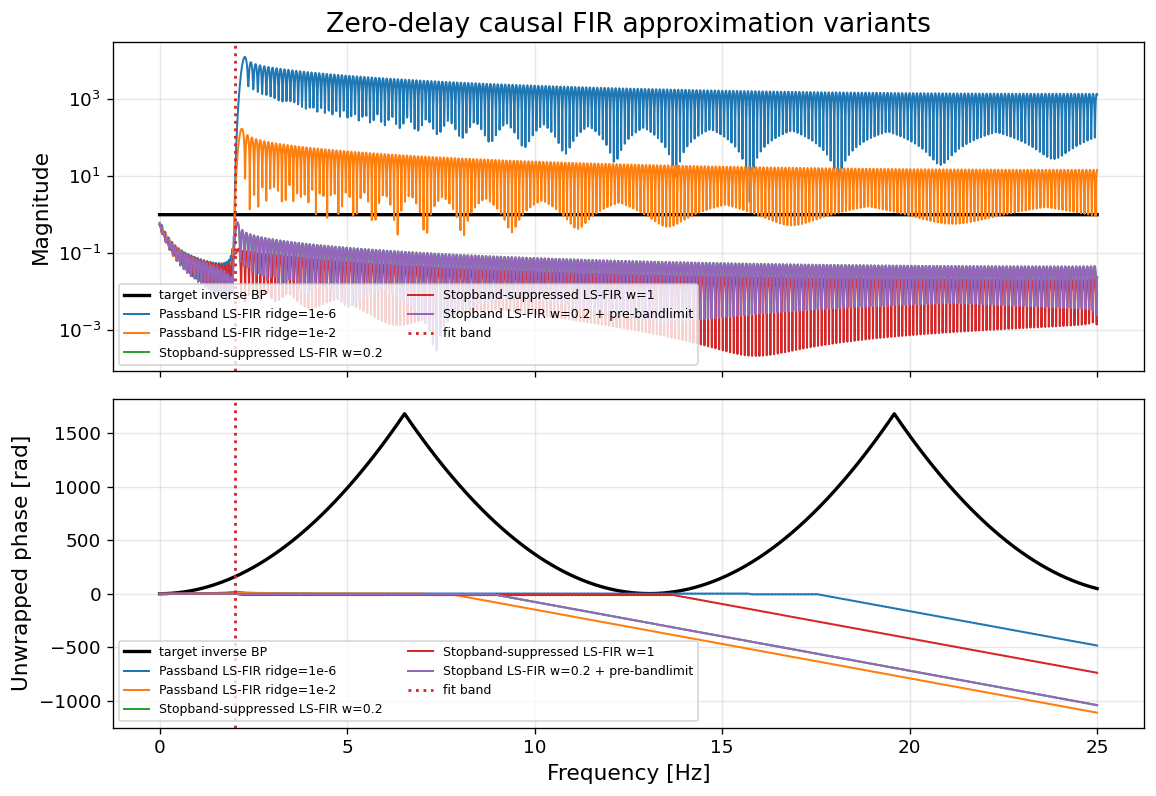

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(9.8, 6.8), sharex=True)
w = response_error_df[response_error_df["variant"].eq(causal_results[0]["name"])] ["frequency_hz"].to_numpy()
H_target_pos = inverse_backprop_response(w, rho_over_v)
axes[0].semilogy(w, np.abs(H_target_pos), "k", linewidth=2, label="target inverse BP")
axes[1].plot(w, np.unwrap(np.angle(H_target_pos)), "k", linewidth=2, label="target inverse BP")

for result in causal_results:
    w, H_causal = freqz(result["h"], worN=4096, fs=Fs)
    axes[0].semilogy(w, np.maximum(np.abs(H_causal), 1e-8), linewidth=1.2, label=result["label"])
    axes[1].plot(w, np.unwrap(np.angle(H_causal)), linewidth=1.2, label=result["label"])

for ax in axes:
    ax.axvline(fit_band_hz, color="tab:red", linestyle=":", label="fit band")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7.5, ncol=2)
axes[0].set_ylabel("Magnitude")
axes[0].set_title("Zero-delay causal FIR approximation variants")
axes[1].set_xlabel("Frequency [Hz]")
axes[1].set_ylabel("Unwrapped phase [rad]")
fig.tight_layout(pad=1.1)
fig.savefig(output_dir / "causal_fir_frequency_response.png", dpi=300)
plt.show()


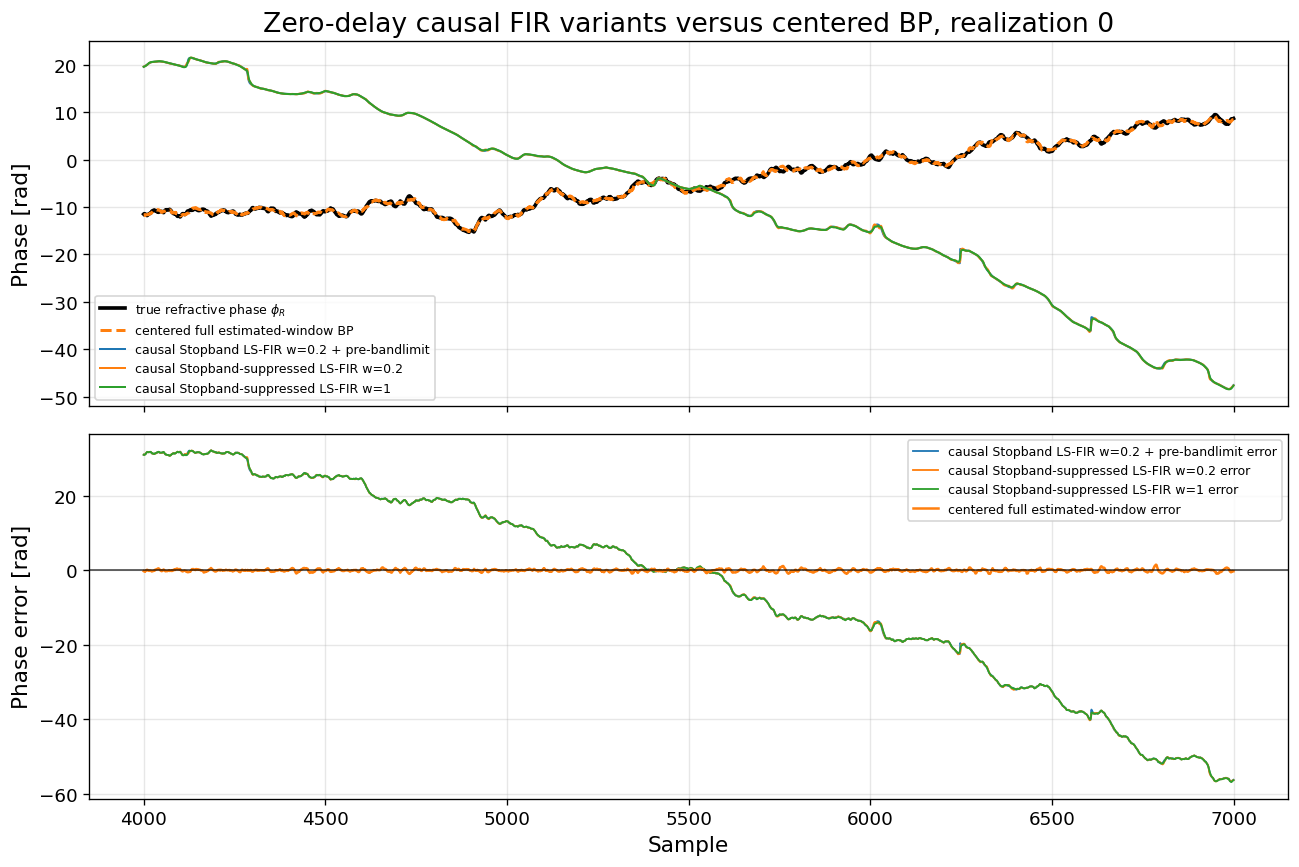

In [5]:
plot_stop = min(plot_start + plot_len, valid_stop)
plot_start_eff = max(plot_start, valid_start)
sl = slice(plot_start_eff, plot_stop)
samples = np.arange(plot_start_eff, plot_stop)
plot_idx = np.zeros(N, dtype=bool)
plot_idx[sl] = True

phase_ref = np.unwrap(np.angle(u_screen))
phase_received = median_align_to_reference(np.unwrap(np.angle(u_est)), phase_ref, plot_idx)
phase_centered = median_align_to_reference(unwrap_finite_phase(psi_centered_full_estimated), phase_ref, plot_idx)
phase_centered_true = median_align_to_reference(unwrap_finite_phase(psi_centered_true_scint), phase_ref, plot_idx)
phase_best_causal = median_align_to_reference(unwrap_finite_phase(best_causal["psi"]), phase_ref, plot_idx)

top_causal_variants = metrics_df[metrics_df["method"].str.startswith("Causal")].head(3)["variant"].tolist()
phase_by_variant = {
    result["name"]: median_align_to_reference(unwrap_finite_phase(result["psi"]), phase_ref, plot_idx)
    for result in causal_results
    if result["name"] in top_causal_variants
}

phase_example_df = pd.DataFrame(
    {
        "sample": samples,
        "refractive_phase_rad": phase_ref[sl],
        "received_estimated_phase_aligned_rad": phase_received[sl],
        "centered_full_estimated_phase_aligned_rad": phase_centered[sl],
        "centered_true_scint_phase_aligned_rad": phase_centered_true[sl],
        "best_causal_variant": best_causal["name"],
        "best_causal_phase_aligned_rad": phase_best_causal[sl],
        "best_causal_phase_error_rad": phase_best_causal[sl] - phase_ref[sl],
        "centered_full_estimated_phase_error_rad": phase_centered[sl] - phase_ref[sl],
        "centered_true_scint_phase_error_rad": phase_centered_true[sl] - phase_ref[sl],
    }
)
for variant, phase in phase_by_variant.items():
    phase_example_df[f"{variant}_phase_aligned_rad"] = phase[sl]
    phase_example_df[f"{variant}_phase_error_rad"] = phase[sl] - phase_ref[sl]
phase_example_df.to_csv(output_dir / "causal_fir_vs_centered_phase_example.csv", index=False)

fig, axes = plt.subplots(2, 1, figsize=(11.0, 7.4), sharex=True)
axes[0].plot(samples, phase_ref[sl], "k", linewidth=2.2, label=r"true refractive phase $\phi_R$")
axes[0].plot(samples, phase_centered[sl], "--", color="tab:orange", linewidth=1.8, label="centered full estimated-window BP")

for variant in top_causal_variants:
    result = next(item for item in causal_results if item["name"] == variant)
    phase = phase_by_variant[variant]
    axes[0].plot(samples, phase[sl], linewidth=1.2, label=f"causal {result['label']}")
    axes[1].plot(samples, phase[sl] - phase_ref[sl], linewidth=1.1, label=f"causal {result['label']} error")

axes[1].plot(samples, phase_centered[sl] - phase_ref[sl], color="tab:orange", linewidth=1.5, label="centered full estimated-window error")
axes[1].axhline(0, color="k", linewidth=1.0, alpha=0.7)

axes[0].set_ylabel("Phase [rad]")
axes[0].set_title(f"Zero-delay causal FIR variants versus centered BP, realization {example_realization_idx}")
axes[1].set_xlabel("Sample")
axes[1].set_ylabel("Phase error [rad]")
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend(ncol=1, fontsize=7.5)
fig.tight_layout(pad=1.1)
fig.savefig(output_dir / "causal_fir_vs_centered_phase_example.png", dpi=300)
plt.show()


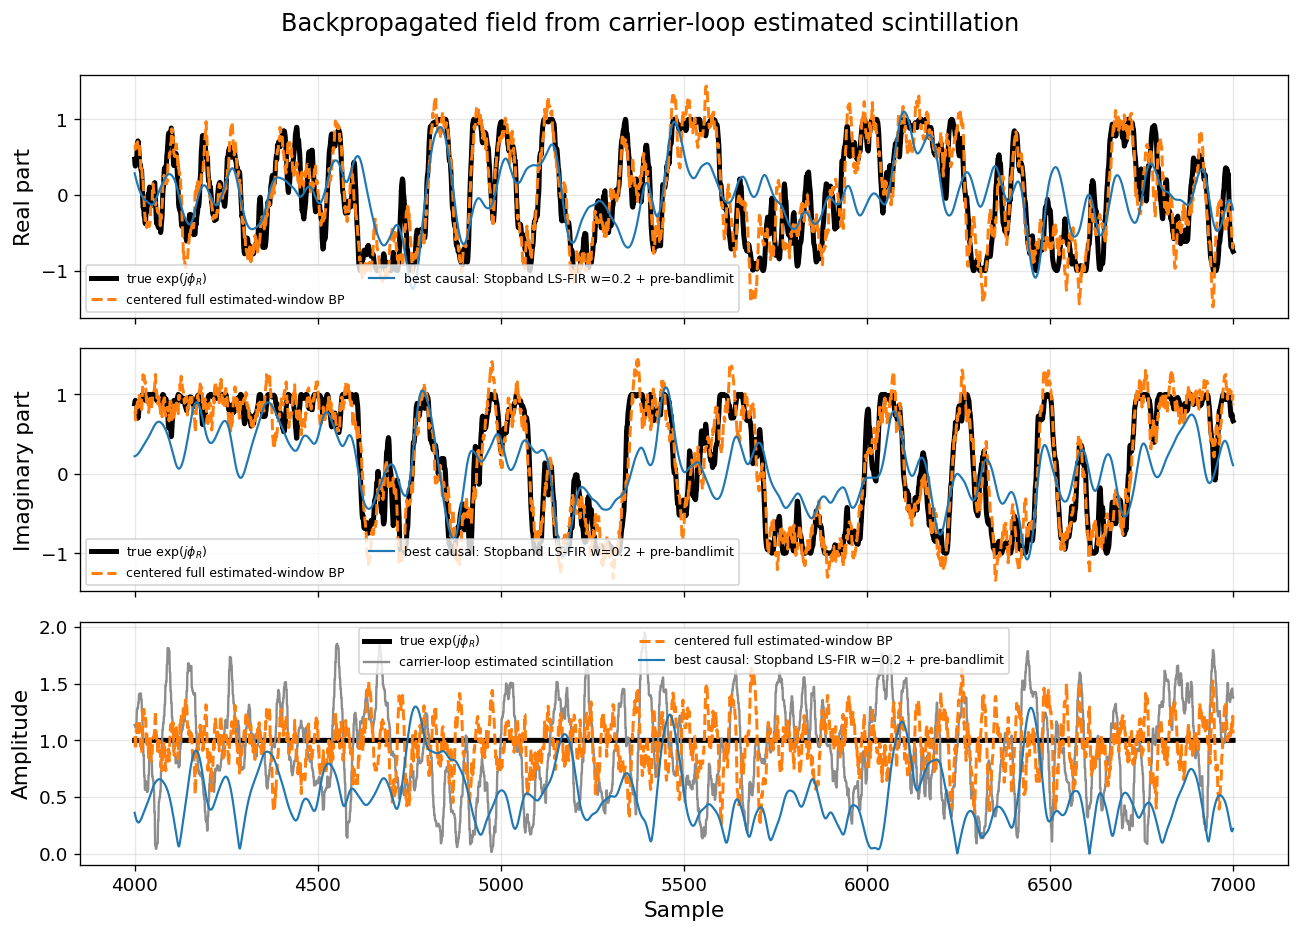

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(11.0, 7.8), sharex=True)
axes[0].plot(samples, np.real(u_screen[sl]), "k", linewidth=3.0, label=r"true $\exp(j\phi_R)$")
axes[0].plot(samples, np.real(psi_centered_full_estimated[sl]), "--", color="tab:orange", linewidth=1.8, label="centered full estimated-window BP")
axes[0].plot(samples, np.real(best_causal["psi"][sl]), color="tab:blue", linewidth=1.3, label=f"best causal: {best_causal['label']}")

axes[1].plot(samples, np.imag(u_screen[sl]), "k", linewidth=3.0, label=r"true $\exp(j\phi_R)$")
axes[1].plot(samples, np.imag(psi_centered_full_estimated[sl]), "--", color="tab:orange", linewidth=1.8, label="centered full estimated-window BP")
axes[1].plot(samples, np.imag(best_causal["psi"][sl]), color="tab:blue", linewidth=1.3, label=f"best causal: {best_causal['label']}")

axes[2].plot(samples, np.abs(u_screen[sl]), "k", linewidth=3.0, label=r"true $\exp(j\phi_R)$")
axes[2].plot(samples, np.abs(u_est[sl]), color="0.55", linewidth=1.4, label="carrier-loop estimated scintillation")
axes[2].plot(samples, np.abs(psi_centered_full_estimated[sl]), "--", color="tab:orange", linewidth=1.8, label="centered full estimated-window BP")
axes[2].plot(samples, np.abs(best_causal["psi"][sl]), color="tab:blue", linewidth=1.3, label=f"best causal: {best_causal['label']}")

axes[0].set_ylabel("Real part")
axes[1].set_ylabel("Imaginary part")
axes[2].set_ylabel("Amplitude")
axes[2].set_xlabel("Sample")
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend(ncol=2, fontsize=7.5)
fig.suptitle("Backpropagated field from carrier-loop estimated scintillation", y=0.995)
fig.tight_layout(pad=1.1)
fig.savefig(output_dir / "causal_fir_vs_centered_field_example.png", dpi=300)
plt.show()


## Notes

All causal variants remain zero-added-delay filters: the output at sample `k` uses only samples `k, k-1, ...`. The variants test whether the naive passband least-squares FIR failure can be controlled without adding explicit delay by using stronger Tikhonov regularization, explicit stopband suppression, and optional pre-bandlimiting of the input. The centered full estimated-window FFT BP remains the finite-window reference because it uses both past and future carrier-loop estimated scintillation samples.
